# Music Recording Identification with Spectral Fingerprints
**DSP501 · Digital Signal Processing**

This study asks whether a five-second excerpt with an unknown start time identifies its source recording. It uses spectral peak pairs and time-offset voting, with a fixed acceptance rule shared by the Streamlit app.

**Main result.** The system identified 120 of 135 queries from indexed recordings (88.9%) and rejected all 45 queries from withheld recordings. At −3 dB SNR, the correct recording ranked first for 43 of 45 queries and was accepted for 31. The withheld queries came from five distinct recordings.

## 1. Setup

Run in Jupyter from the repository or its `notebooks/` directory. The checked-in counts reproduce the tables and figures. With the original local dataset, Section 6 also recomputes the holdout from the audio and compares it with the saved counts.

In [1]:
import os
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import display
from scipy.signal import get_window

root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "prototypes/fingerprint.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Start Jupyter within the project checkout.")

sys.path.insert(0, str(root / "prototypes"))
import fingerprint as fp

dataset = Path(os.environ.get("DSP501_DATASET", root / "data/processed/loudio-hits"))
conditions = {"clean": "Clean", "snr10": "+10 dB", "snr-3": "−3 dB"}
accent, neutral, highlight = "#08786d", "#566c87", "#a94d31"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 11, "axes.titlesize": 12, "figure.dpi": 120})

## 2. Method
### Short-time Fourier transform

Convert to mono and resample to 12 kHz. Multiply each 1,024-sample frame by a Hann window and compute its DFT with an FFT. A 240-sample hop gives a 20 ms time grid; adjacent frequency bins are approximately 11.72 Hz apart.

$$X[m,k] = \sum_{n=0}^{N-1} x[mH+n] \, w[n] \, e^{-j2\pi kn/N}.$$

### Spectral peak pairs

Select local maxima in an 11-bin by 13-frame neighborhood, within 120–3,500 Hz and above 1.8% of the clip's maximum STFT magnitude. Pair each anchor with up to eight later peaks, 5–45 hops away. The key contains the two frequency bins quantized in steps of two and the inter-peak delay quantized in steps of two hops. The index stores each key with a recording identifier and the anchor frame.

### Time-offset voting

For a shared key, the vote goes to $d=m_{\text{reference}}-m_{\text{query}}$. A recording's score is the maximum combined count across any three neighboring offset bins. Accept the leading recording if its score is at least eight votes and at least twice the runner-up score. The central bin gives the estimated start position.

### Inspect the transform and peak map

The following synthetic multitone signal makes the processing steps visible. The holdout evaluation uses music excerpts.

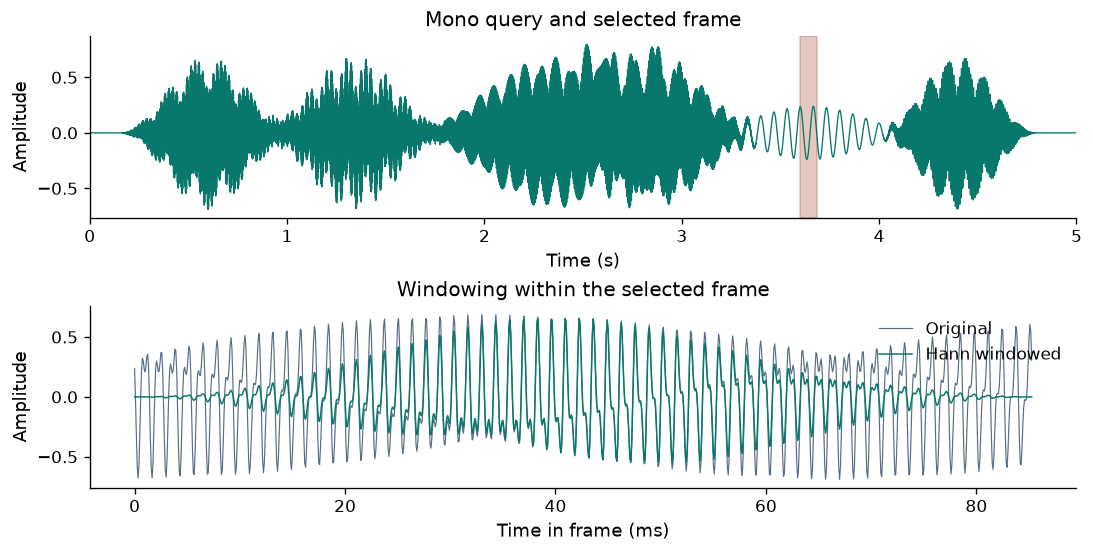

In [2]:
time = np.arange(5 * fp.SR) / fp.SR
signal = np.zeros_like(time)
for onset, duration, frequency in [(0.15, 0.9, 360), (0.84, 1.0, 510), (1.6, 1.5, 640),
                                   (2.32, 1.1, 430), (3.05, 1.2, 750), (4.0, 0.8, 540)]:
    active = (time >= onset) & (time < onset + duration)
    local_time = time[active] - onset
    envelope = np.sin(np.pi * local_time / duration) ** 2
    signal[active] += envelope * (
        0.45 * np.sin(2 * np.pi * frequency * local_time)
        + 0.24 * np.sin(2 * np.pi * 2.02 * frequency * local_time)
    )

frequency, frame_time, transform = fp.spectrum(signal)
magnitude = np.abs(transform)
peaks = fp.spectral_peaks(frequency, magnitude)
first_pair = next(fp.fingerprint_pairs(peaks), None)
frame_id = int(np.argmax(magnitude.max(axis=0)))
start = frame_id * fp.HOP
frame = signal[start:start + fp.FRAME]
windowed = frame * get_window(fp.WINDOW, fp.FRAME)

fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), layout="constrained")
axes[0].plot(time[::8], signal[::8], color=accent, linewidth=0.8)
axes[0].axvspan(time[start], time[start + fp.FRAME], color=highlight, alpha=0.3)
axes[0].set(title="Mono query and selected frame", xlabel="Time (s)", ylabel="Amplitude",
            xlim=(0, 5))
frame_ms = np.arange(fp.FRAME) * 1000 / fp.SR
axes[1].plot(frame_ms, frame, color=neutral, linewidth=0.7, label="Original")
axes[1].plot(frame_ms, windowed, color=accent, linewidth=0.9, label="Hann windowed")
axes[1].set(title="Windowing within the selected frame", xlabel="Time in frame (ms)",
            ylabel="Amplitude")
axes[1].legend(frameon=False, loc="upper right")
plt.show()

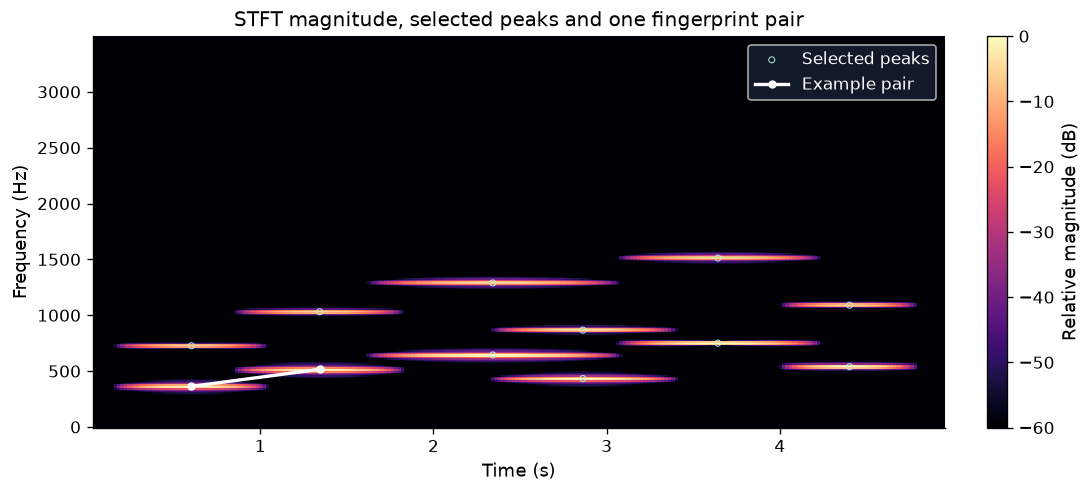

In [3]:
visible = frequency <= 3500
level_db = 20 * np.log10(np.maximum(magnitude[visible] / magnitude.max(), 1e-3))
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
image = ax.pcolormesh(frame_time, frequency[visible], level_db, shading="auto",
                      cmap="magma", vmin=-60, vmax=0)
peak_frame, peak_bin = np.asarray(peaks).T
ax.scatter(frame_time[peak_frame], frequency[peak_bin], facecolors="none",
           edgecolors="#adf2df", s=13, linewidths=0.6, label="Selected peaks")
if first_pair:
    _, (left, bottom), (right, top) = first_pair
    ax.plot(frame_time[[left, right]], frequency[[bottom, top]], "-o",
            color="white", markersize=4, linewidth=2, label="Example pair")
ax.set(title="STFT magnitude, selected peaks and one fingerprint pair",
       xlabel="Time (s)", ylabel="Frequency (Hz)")
ax.legend(loc="upper right", facecolor="#172032", labelcolor="white")
fig.colorbar(image, ax=ax, label="Relative magnitude (dB)")
plt.show()

## 3. Data and experimental protocol

The corpus contains 100 recordings selected by cumulative play count. The index uses the first 45 seconds from 90 recordings. The remaining 10 were withheld. Three non-overlapping five-second excerpts per recording were kept clean and mixed with Gaussian white noise at +10 and −3 dB SNR, giving 900 query variants in the full corpus.

The final test uses 15 indexed and five withheld recordings, for 45 indexed and 15 withheld queries per noise condition. Noise variants reuse the same source excerpts. The test applies the fixed acceptance rule without tuning on the final holdout. Correct identification is measured on indexed queries and correct rejection on withheld queries.

An indexed query comes from the same recording and time span available to the index. The holdout measures recognition of the source recording under controlled noise. The browser demo uses a separate index of all 100 recordings.

In [4]:
protocol = pd.DataFrame(
    [
        ("Reference only", 60, "Indexed"),
        ("Calibration queries", 15, "Indexed"),
        ("Calibration queries", 5, "Withheld"),
        ("Final test queries", 15, "Indexed"),
        ("Final test queries", 5, "Withheld"),
    ],
    columns=["Recording group", "Distinct recordings", "Membership in the study index"],
)
display(protocol)

,Recording group,Distinct recordings,Membership in the study index
0,Reference only,60,Indexed
1,Calibration queries,15,Indexed
2,Calibration queries,5,Withheld
3,Final test queries,15,Indexed
4,Final test queries,5,Withheld


## 4. Results by noise level

Load the fixed-rule rows from the original open-set evaluation. The repository contains aggregate counts in `results/holdout_metrics.csv`. The unit of the counts below is a query clip.

In [5]:
counts = pd.read_csv(root / "results/holdout_metrics.csv").set_index("condition")
assert list(counts.index) == list(conditions)
assert (counts["known_n"] == 45).all() and (counts["unknown_n"] == 15).all()
assert (counts.known_correct + counts.known_wrong + counts.known_rejected == counts.known_n).all()
assert (counts.unknown_rejected + counts.unknown_false_accept == counts.unknown_n).all()

summary = counts.copy()
summary.loc["All conditions"] = counts.sum()
summary = summary.rename(index=conditions)
identification = summary.known_correct / summary.known_n
rejection = summary.unknown_rejected / summary.unknown_n
display(pd.DataFrame({
    "Correct identifications": summary.known_correct.astype(str) + " / " + summary.known_n.astype(str),
    "Identification rate": identification.map("{:.1%}".format),
    "Indexed queries rejected": summary.known_rejected,
    "Wrong recordings accepted": summary.known_wrong,
    "Correct rejections": summary.unknown_rejected.astype(str) + " / " + summary.unknown_n.astype(str),
    "Rejection rate": rejection.map("{:.1%}".format),
}).rename_axis("Query condition"))

,Correct identifications,Identification rate,Indexed queries rejected,Wrong recordings accepted,Correct rejections,Rejection rate
Query condition,,,,,,
Clean,45 / 45,100.0%,0,0,15 / 15,100.0%
+10 dB,44 / 45,97.8%,1,0,15 / 15,100.0%
−3 dB,31 / 45,68.9%,14,0,15 / 15,100.0%
All conditions,120 / 135,88.9%,15,0,45 / 45,100.0%


## 5. Error analysis

The ranking answers which recording received the most support. The rule then decides whether that candidate has enough evidence. Comparing both counts locates the main loss at −3 dB.

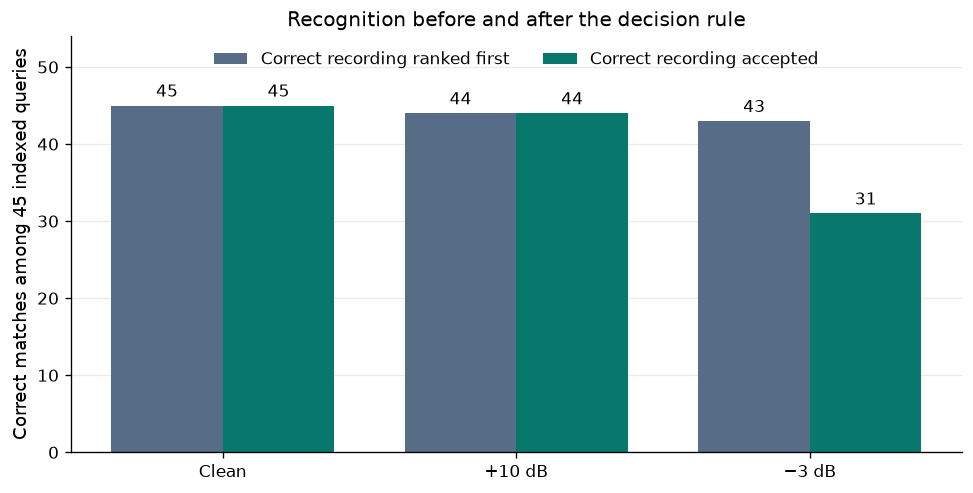

In [6]:
positions = np.arange(len(conditions))
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ranked = ax.bar(positions - 0.19, counts.known_top1_before_threshold, width=0.38,
                color=neutral, label="Correct recording ranked first")
accepted = ax.bar(positions + 0.19, counts.known_correct, width=0.38,
                  color=accent, label="Correct recording accepted")
ax.bar_label(ranked, padding=3)
ax.bar_label(accepted, padding=3)
ax.set(title="Recognition before and after the decision rule",
       ylabel="Correct matches among 45 indexed queries",
       xticks=positions, xticklabels=list(conditions.values()), ylim=(0, 54))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncols=2)
plt.show()

strong = counts.loc["snr-3"]
assert strong.known_wrong == 0
assert (strong.known_top1_before_threshold - strong.known_correct) + (
    strong.known_n - strong.known_top1_before_threshold
) == strong.known_rejected

At −3 dB, the decision rule rejected 12 queries whose highest-scoring candidate was correct. The other two rejected queries ranked the wrong recording first. These counts show where the system lost identifications. A breakdown by failed vote threshold and failed score ratio would require a separate analysis.

## 6. Reproduce the holdout from local audio

Supply the original processed corpus using the `DSP501_DATASET` environment variable, or place it under `data/processed/loudio-hits/`. This directory must contain `tracks.csv`, `queries.csv`, `references/` and `queries/`. All public sections above also run when the corpus folder is absent. The code below validates clip lengths, builds the 90-recording study index and checks every aggregate against the published counts.

In [7]:
def read_mono_clip(relative_path, seconds):
    path = (dataset / relative_path).resolve()
    if not path.is_relative_to(dataset.resolve()):
        raise ValueError("An audio path escapes the local dataset directory.")
    wave, rate = sf.read(path, dtype="float32")
    if rate != fp.SR or wave.shape != (seconds * fp.SR,) or not np.isfinite(wave).all():
        raise ValueError("The processed audio does not match the study format.")
    return wave


def recompute_holdout():
    tracks = pd.read_csv(dataset / "tracks.csv")
    queries = pd.read_csv(dataset / "queries.csv")
    assert len(tracks) == 100 and tracks.song_id.is_unique
    assert len(queries) == 900 and queries.clip_id.is_unique
    groups = {"reference_only": 60, "calibration_known": 15, "calibration_unknown": 5,
              "test_known": 15, "test_unknown": 5}
    assert tracks.evaluation_split.value_counts().to_dict() == groups

    reference_rows = tracks.loc[tracks.open_set_group.eq("catalog")]
    keys = tuple(reference_rows.song_id)
    assert len(keys) == 90
    titles = dict(zip(reference_rows.song_id, reference_rows.title, strict=True))
    index = fp.build_index({
        row.song_id: read_mono_clip(row.reference_file, fp.REFERENCE_SECONDS)
        for row in reference_rows.itertuples(index=False)
    })

    test = queries.loc[queries.evaluation_split.isin(["test_known", "test_unknown"])]
    assert len(test) == 180 and test.song_id.nunique() == 20
    assert set(test.loc[test.evaluation_split.eq("test_unknown"), "song_id"]).isdisjoint(keys)

    tallies = {condition: Counter() for condition in conditions}
    for row in test.itertuples(index=False):
        wave = read_mono_clip(row.clip_file, 5)
        result = fp.recognize(wave, index, keys, titles=titles)
        match = result["match"]
        tally = tallies[row.condition]
        if row.song_id in titles:
            tally["known_n"] += 1
            tally["known_top1_before_threshold"] += result["candidates"][0]["key"] == row.song_id
            if match is None:
                tally["known_rejected"] += 1
            elif match["key"] == row.song_id:
                tally["known_correct"] += 1
            else:
                tally["known_wrong"] += 1
        else:
            tally["unknown_n"] += 1
            tally["unknown_rejected" if match is None else "unknown_false_accept"] += 1

    return (
        pd.DataFrame.from_dict(tallies, orient="index")
        .reindex(index=counts.index, columns=counts.columns)
        .fillna(0)
        .astype(int)
    )


if not (dataset / "tracks.csv").exists():
    print("Public result mode. Set DSP501_DATASET to rerun the audio evaluation.")
else:
    rerun = recompute_holdout()
    pd.testing.assert_frame_equal(rerun, counts.astype(int))
    print("Local reproduction matched all published holdout counts.")

Public result mode. Set DSP501_DATASET to rerun the audio evaluation.


## 7. Conclusion and limits

Spectral fingerprints gave 88.9% correct identification in the five-second holdout and rejected all 45 withheld clips. The rejection count covers five distinct recordings, and noise injection used paired variants of the same excerpts. Real microphone captures, alternate performances, and start-time error are next evaluation targets. They require their own test data.

**References**

1. J. B. Allen and L. R. Rabiner (1977). [A Unified Approach to Short-Time Fourier Analysis and Synthesis](https://doi.org/10.1109/PROC.1977.10770). *Proceedings of the IEEE*, 65(11), 1558–1564.
2. A. L.-C. Wang (2003). [An Industrial-Strength Audio Search Algorithm](https://www.ee.columbia.edu/~dpwe/papers/Wang03-shazam.pdf). *ISMIR 2003*.
3. DSP501 local open-set evaluation, `data/processed/loudio-hits/03-loudio-hits-evaluation.ipynb` and `test_metrics.csv`. The fixed-rule counts are reproduced here. The [Streamlit demonstration](https://music-recognition.streamlit.app/) exposes the same DSP pipeline with a 100-recording index.